# 02 — Análise Exploratória dos Dados (EDA) com foco em negócio

**Como ler este notebook:** cada seção responde a uma **pergunta de negócio** do enunciado. Depois de cada gráfico há um bloco **"Em linguagem de gestão"**, escrito para um(a) gerente de operações que não precisa entender estatística.

Perguntas que vamos responder:
1. Qual é o retrato atual da satisfação?
2. Quais fatores parecem mais críticos para a satisfação?
3. O que mais gera detratores?
4. Existe algum "ponto de ruptura" na experiência do cliente?
5. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?
6. Por que isso importa? (NPS x recompra)

In [1]:
# Configuração: permite importar o pacote "src" a partir da pasta notebooks/
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src import config
from src.data_preparation import load_processed_data, calculate_nps
from src.visualization import set_plot_style, save_figure, summarize_by_group, plot_score_and_detractors

set_plot_style()
df = load_processed_data()
print(f"{len(df):,} pedidos carregados da base tratada")

2,500 pedidos carregados da base tratada


## 1. Retrato atual: como está a satisfação dos clientes?

In [2]:
overall_nps = calculate_nps(df["nps_score"])
category_share = df["nps_category"].value_counts(normalize=True).reindex(["Detrator", "Neutro", "Promotor"]).mul(100)

print(f"Nota média      : {df['nps_score'].mean():.1f}")
print(f"Nota mediana    : {df['nps_score'].median():.1f}")
print(f"NPS da empresa  : {overall_nps:+.0f}")
print(category_share.round(1).to_string())

Nota média      : 4.4
Nota mediana    : 4.4
NPS da empresa  : -80
nps_category
Detrator    84.4
Neutro      11.2
Promotor     4.4


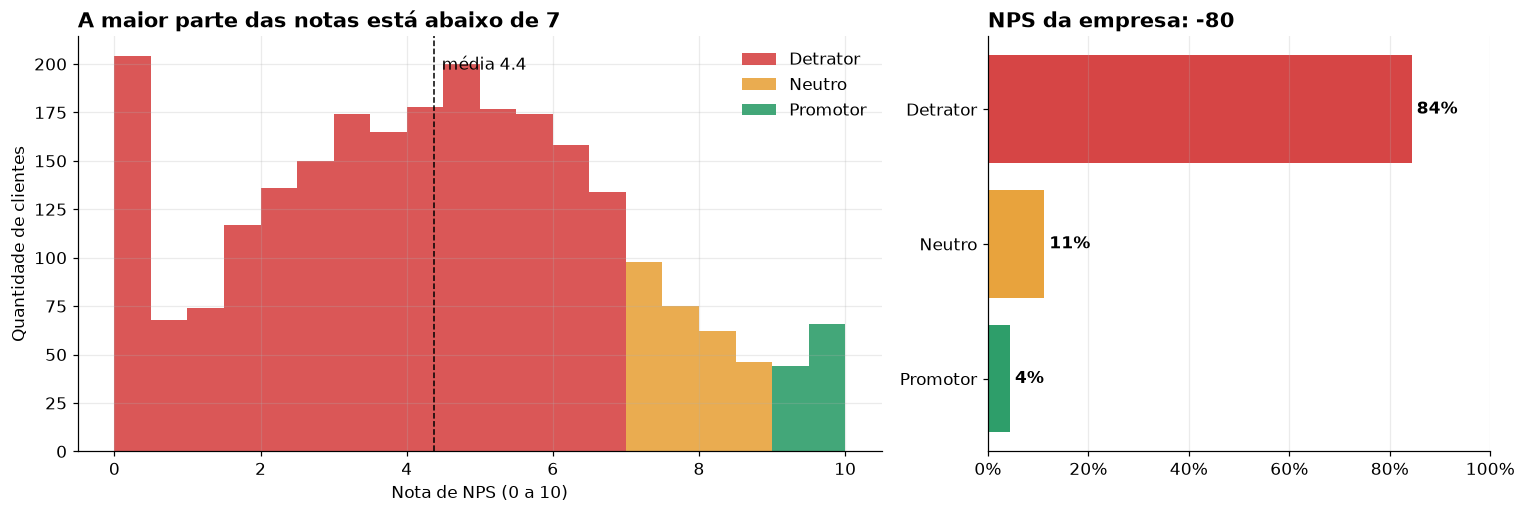

In [3]:
fig, (ax_hist, ax_bar) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

# Histograma colorido pela categoria do NPS
bins = np.arange(0, 10.5, 0.5)
for category, color in [("Detrator", config.COLOR_DETRACTOR), ("Neutro", config.COLOR_NEUTRAL), ("Promotor", config.COLOR_PROMOTER)]:
    ax_hist.hist(df.loc[df["nps_category"] == category, "nps_score"], bins=bins, color=color, label=category, alpha=0.9)
ax_hist.axvline(df["nps_score"].mean(), color="black", linestyle="--", linewidth=1)
ax_hist.text(df["nps_score"].mean() + 0.1, ax_hist.get_ylim()[1] * 0.92, f"média {df['nps_score'].mean():.1f}")
ax_hist.set_title("A maior parte das notas está abaixo de 7")
ax_hist.set_xlabel("Nota de NPS (0 a 10)")
ax_hist.set_ylabel("Quantidade de clientes")
ax_hist.legend(frameon=False)

# Barras com a participação de cada categoria
colors = [config.COLOR_DETRACTOR, config.COLOR_NEUTRAL, config.COLOR_PROMOTER]
ax_bar.barh(category_share.index[::-1], category_share.values[::-1], color=colors[::-1])
for y, value in enumerate(category_share.values[::-1]):
    ax_bar.text(value + 1, y, f"{value:.0f}%", va="center", fontweight="bold")
ax_bar.set_xlim(0, 100)
ax_bar.xaxis.set_major_formatter(mticker.PercentFormatter())
ax_bar.set_title(f"NPS da empresa: {overall_nps:+.0f}")
ax_bar.grid(axis="y", visible=False)

plt.tight_layout()
save_figure(fig, "fig01_distribuicao_nps.png")
plt.show()

**Em linguagem de gestão:**
- De cada 100 clientes, **84 são detratores** (falariam mal da empresa), 11 são neutros e **só 4 são promotores**.
- O NPS da empresa é **-80**. Para comparação, um NPS acima de 0 já é considerado razoável e acima de 50 é considerado excelente. **A satisfação está em nível crítico.**
- Como quase todo mundo é detrator, a pergunta mais útil não é "quem é detrator", e sim **"o que faz alguém sair do vermelho?"**

## 2. Quais fatores parecem mais críticos para a satisfação?

In [4]:
# Correlação de Spearman: mede se "quando X sobe, a nota sobe (ou desce)".
# Usamos Spearman porque ela é robusta a outliers e a relações não lineares.
factor_labels = {
    "delivery_delay_days": ("Dias de atraso na entrega", "Logística"),
    "complaints_count": ("Nº de reclamações", "Atendimento"),
    "customer_service_contacts": ("Nº de contatos com o SAC", "Atendimento"),
    "resolution_time_days": ("Tempo de resolução", "Atendimento"),
    "freight_value": ("Valor do frete", "Logística"),
    "delivery_time_days": ("Tempo total de entrega", "Logística"),
    "delivery_attempts": ("Tentativas de entrega", "Logística"),
    "order_value": ("Valor do pedido", "Pedido"),
    "discount_value": ("Valor do desconto", "Pedido"),
    "items_quantity": ("Quantidade de itens", "Pedido"),
    "payment_installments": ("Nº de parcelas", "Pedido"),
    "customer_age": ("Idade", "Perfil do cliente"),
    "customer_tenure_months": ("Tempo de relacionamento", "Perfil do cliente"),
}
correlations = (
    df[list(factor_labels) + ["nps_score"]]
    .corr(method="spearman")["nps_score"]
    .drop("nps_score")
    .rename("correlacao")
    .to_frame()
)
correlations["fator"] = [factor_labels[c][0] for c in correlations.index]
correlations["area"] = [factor_labels[c][1] for c in correlations.index]
correlations = correlations.reindex(correlations["correlacao"].abs().sort_values().index)
correlations.round(3).iloc[::-1]

,correlacao,fator,area
delivery_delay_days,-0.586,Dias de atraso na entrega,Logística
complaints_count,-0.490,Nº de reclamações,Atendimento
customer_service_contacts,-0.336,Nº de contatos com o SAC,Atendimento
resolution_time_days,-0.190,Tempo de resolução,Atendimento
freight_value,-0.040,Valor do frete,Logística
order_value,0.036,Valor do pedido,Pedido
payment_installments,0.027,Nº de parcelas,Pedido
delivery_attempts,0.026,Tentativas de entrega,Logística
customer_tenure_months,-0.012,Tempo de relacionamento,Perfil do cliente
discount_value,0.012,Valor do desconto,Pedido


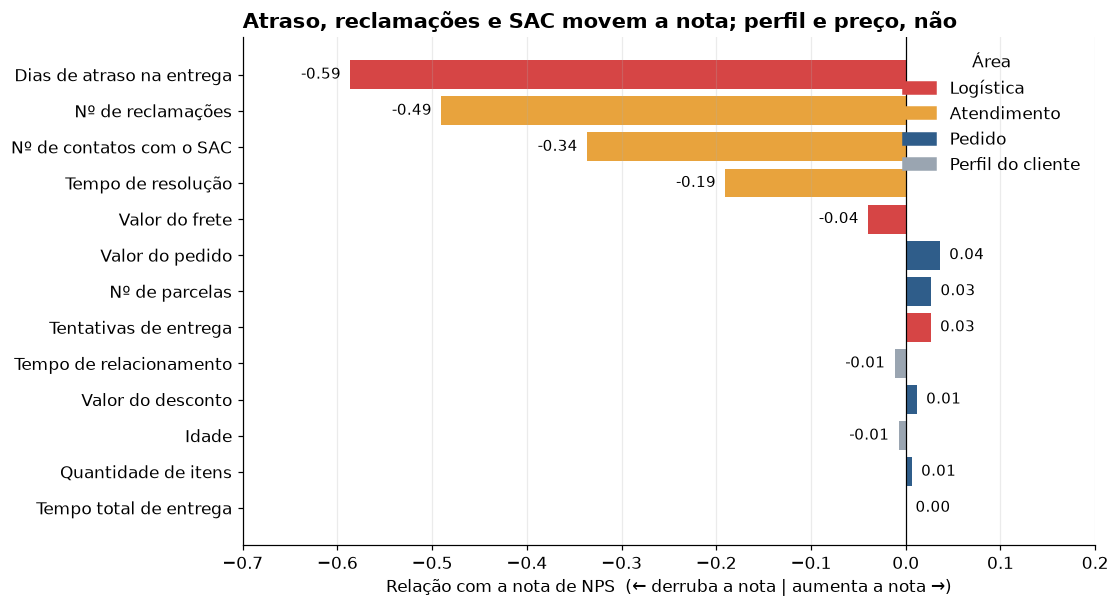

In [5]:
area_colors = {"Logística": config.COLOR_DETRACTOR, "Atendimento": config.COLOR_NEUTRAL,
               "Pedido": config.COLOR_PRIMARY, "Perfil do cliente": config.COLOR_MUTED}

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(correlations["fator"], correlations["correlacao"], color=correlations["area"].map(area_colors))
ax.axvline(0, color="black", linewidth=0.8)
for y, value in enumerate(correlations["correlacao"]):
    ax.text(value - 0.01 if value < 0 else value + 0.01, y, f"{value:.2f}", va="center",
            ha="right" if value < 0 else "left", fontsize=10)
ax.set_xlim(-0.7, 0.2)
ax.set_xlabel("Relação com a nota de NPS  (← derruba a nota | aumenta a nota →)")
ax.set_title("Atraso, reclamações e SAC movem a nota; perfil e preço, não")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in area_colors.values()]
ax.legend(handles, area_colors.keys(), loc="upper right", frameon=False, title="Área")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig02_fatores_correlacao.png")
plt.show()

**Em linguagem de gestão:**
- **Atraso na entrega é, de longe, o fator nº 1.** Quanto mais dias de atraso, menor a nota.
- Em seguida vêm **reclamações** e **contatos com o SAC**. Cliente que precisa reclamar ou ligar já está tendo uma experiência ruim.
- O **tempo de resolução** pesa, mas menos.
- **Preço, desconto, frete, parcelas, idade, região e tempo de casa praticamente não mudam a nota.** Dar desconto não "compra" satisfação se a entrega atrasa.
- Curiosidade importante: o **tempo total de entrega não importa, mas o atraso importa muito**. O cliente aceita esperar 14 dias se esse for o prazo prometido. O que ele não aceita é a **promessa quebrada**.

## 3. O que mais gera detratores?

### 3.1 Atraso na entrega

In [6]:
delay_summary = summarize_by_group(df, "delay_bucket")
delay_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps
delay_bucket,,,,,
Sem atraso,277,6.86,51.62,18.05,-33.6
1 dia,615,5.55,73.98,7.15,-66.8
2 dias,646,4.58,87.93,2.01,-85.9
3 dias,525,3.44,96.76,0.57,-96.2
4+ dias,437,2.00,99.54,0.00,-99.5


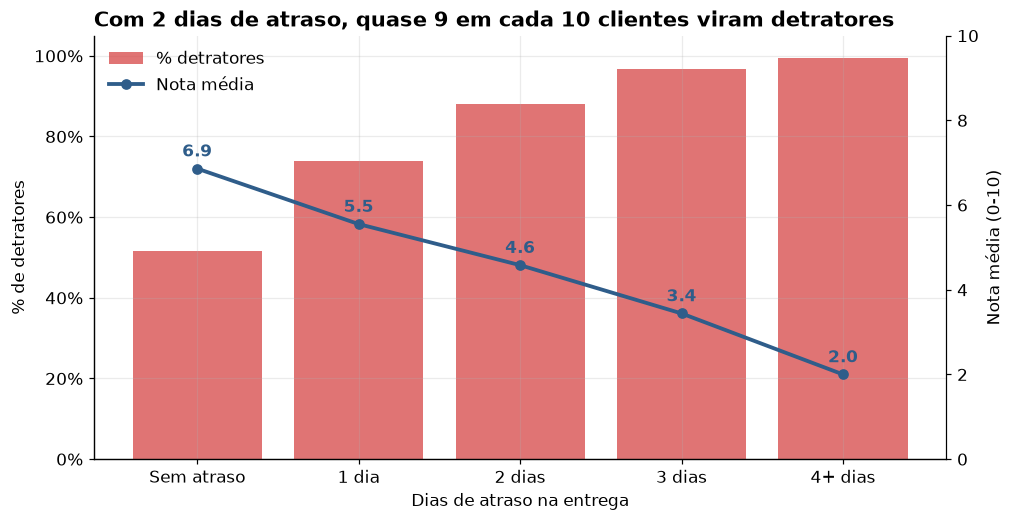

Pedidos com algum atraso: 89%


In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_score_and_detractors(delay_summary, "Com 2 dias de atraso, quase 9 em cada 10 clientes viram detratores",
                          "Dias de atraso na entrega", ax=ax)
save_figure(fig, "fig03_atraso_entrega.png")
plt.show()

print(f"Pedidos com algum atraso: {df['has_delay'].mean():.0%}")

**Em linguagem de gestão:**
- **89% dos pedidos chegam atrasados.** Só 11% são entregues no prazo. Isso, sozinho, explica boa parte do NPS negativo.
- Mesmo **entregando no prazo**, metade dos clientes ainda é detratora. Ou seja, a pontualidade é necessária, mas não é suficiente (o atendimento também pesa).
- A nota cai **cerca de 1 ponto para cada dia de atraso**: de 6,9 (sem atraso) para 2,0 (4 ou mais dias).

### 3.2 Reclamações

In [8]:
complaints_summary = summarize_by_group(df, "complaints_bucket")
complaints_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps
complaints_bucket,,,,,
0-1,145,7.89,28.28,24.14,-4.1
2-3,784,5.31,75.89,6.89,-69.0
4-5,1044,3.98,91.86,1.92,-89.9
6+,527,2.82,97.53,0.19,-97.3


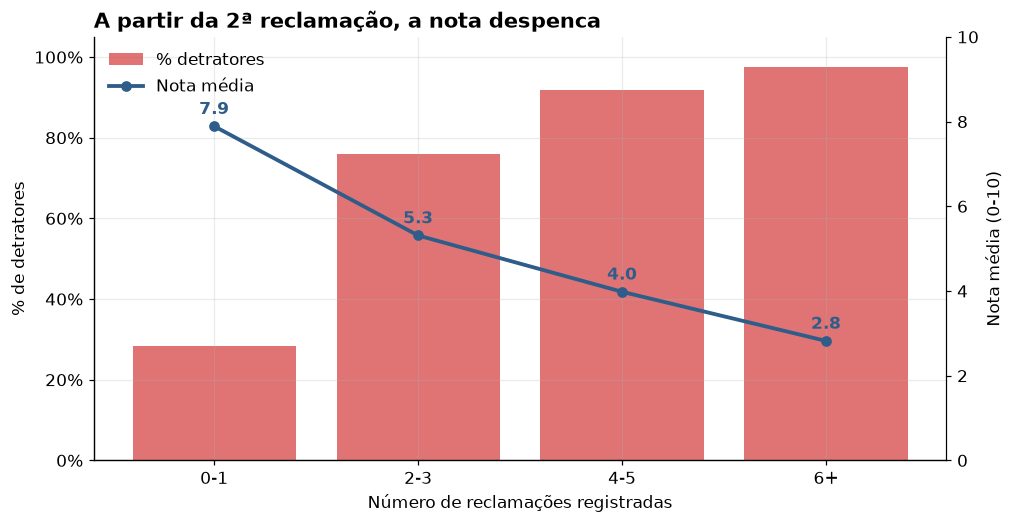

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_score_and_detractors(complaints_summary, "A partir da 2ª reclamação, a nota despenca",
                          "Número de reclamações registradas", ax=ax)
save_figure(fig, "fig04_reclamacoes.png")
plt.show()

**Em linguagem de gestão:**
- Clientes com **0 ou 1 reclamação** têm nota média de **7,9** e "só" 28% de detratores.
- Com **2 ou 3 reclamações** a nota cai para 5,3 e os detratores sobem para 76%.
- Com **6 ou mais**, praticamente todos são detratores.
- **Toda reclamação é um alerta precoce.** É possível agir antes da pesquisa de NPS.

### 3.3 Contatos com o SAC e tempo de resolução

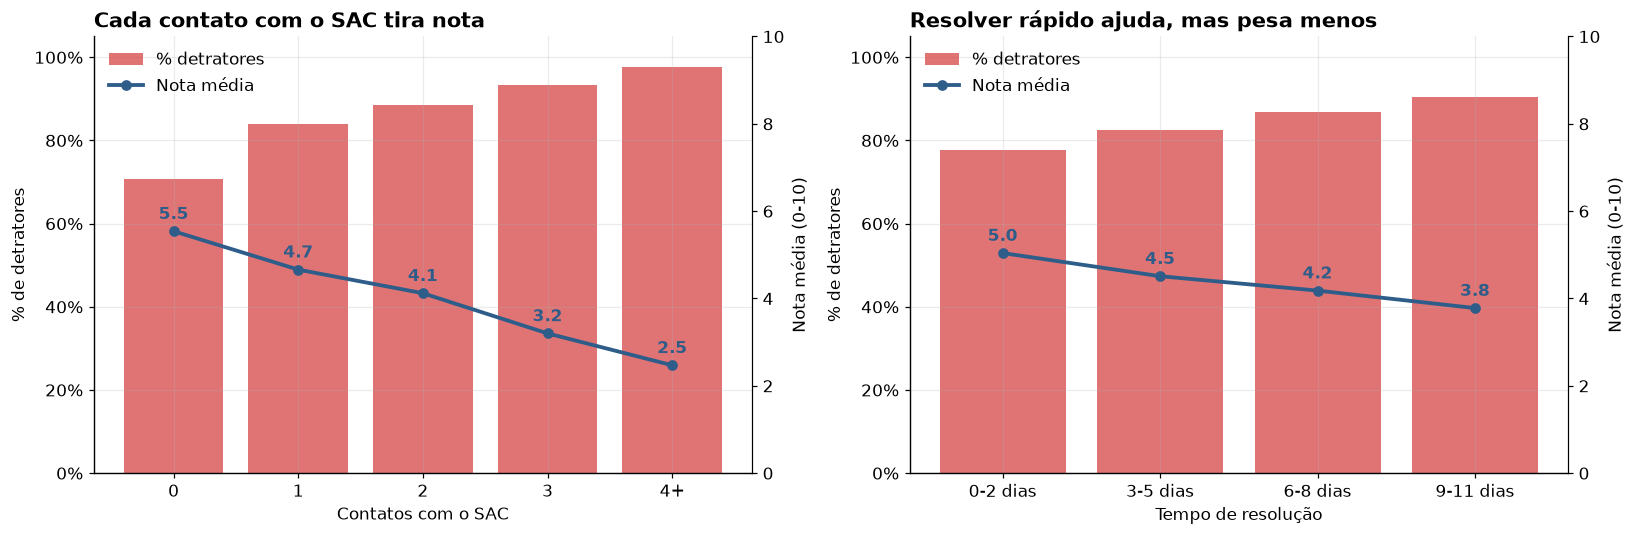

In [10]:
contacts_summary = summarize_by_group(df.assign(contacts=df["customer_service_contacts"].clip(upper=4)), "contacts")
contacts_summary.index = ["0", "1", "2", "3", "4+"]

resolution_bins = pd.cut(df["resolution_time_days"], bins=[-1, 2, 5, 8, 11], labels=["0-2 dias", "3-5 dias", "6-8 dias", "9-11 dias"])
resolution_summary = summarize_by_group(df.assign(resolution=resolution_bins), "resolution")

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(15, 5))
plot_score_and_detractors(contacts_summary, "Cada contato com o SAC tira nota", "Contatos com o SAC", ax=ax_left)
plot_score_and_detractors(resolution_summary, "Resolver rápido ajuda, mas pesa menos", "Tempo de resolução", ax=ax_right)
plt.tight_layout()
save_figure(fig, "fig05_sac_e_resolucao.png")
plt.show()

**Em linguagem de gestão:**
- Quem **não precisou falar com o SAC** tem nota média 5,5. Quem precisou falar **3 vezes** cai para 3,2. Quem falou **4 ou mais vezes** fica em torno de 2,5.
- O cliente não quer um ótimo SAC, ele quer **não precisar do SAC**. Cada contato extra é sinal de que o problema não foi resolvido de primeira.
- O **tempo de resolução** também importa (de 5,0 para 3,8), mas o efeito é menor do que o do número de contatos.

### 3.4 E o que NÃO gera detratores?

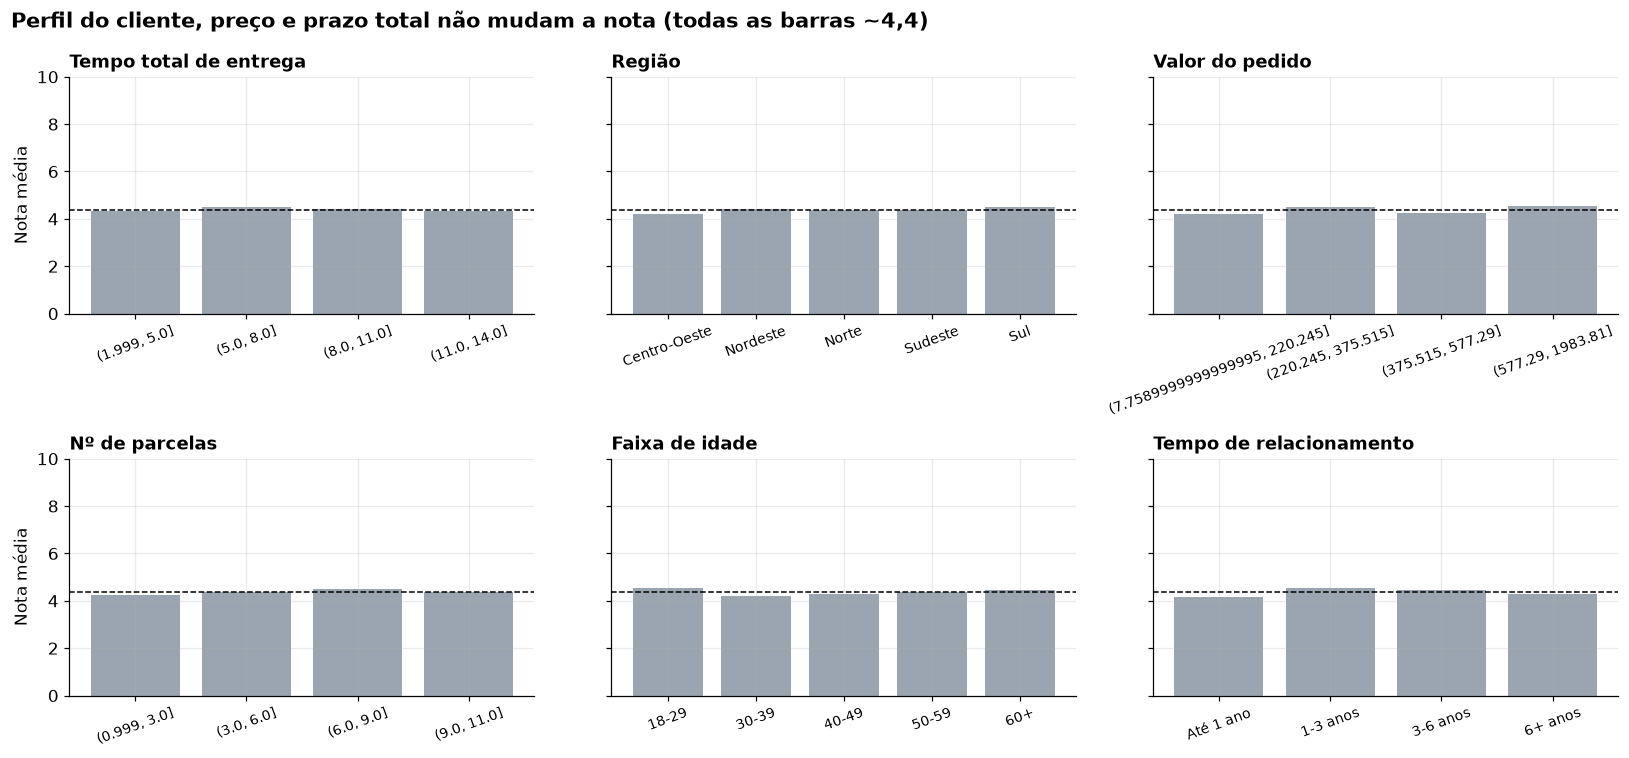

In [11]:
no_impact_factors = {
    "Tempo total de entrega": pd.qcut(df["delivery_time_days"], 4),
    "Região": df["customer_region"],
    "Valor do pedido": pd.qcut(df["order_value"], 4),
    "Nº de parcelas": pd.qcut(df["payment_installments"], 4),
    "Faixa de idade": df["age_group"],
    "Tempo de relacionamento": df["tenure_group"],
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, (label, groups) in zip(axes.flat, no_impact_factors.items()):
    group_means = df.groupby(groups, observed=True)["nps_score"].mean()
    ax.bar(range(len(group_means)), group_means.values, color=config.COLOR_MUTED)
    ax.set_xticks(range(len(group_means)))
    ax.set_xticklabels([str(g) for g in group_means.index], rotation=20, fontsize=9)
    ax.set_title(label, fontsize=12)
    ax.set_ylim(0, 10)
    ax.axhline(df["nps_score"].mean(), color="black", linestyle="--", linewidth=1)
axes[0, 0].set_ylabel("Nota média")
axes[1, 0].set_ylabel("Nota média")
fig.suptitle("Perfil do cliente, preço e prazo total não mudam a nota (todas as barras ~4,4)",
             fontweight="bold", x=0.01, ha="left", fontsize=14)
plt.tight_layout()
save_figure(fig, "fig06_fatores_sem_impacto.png")
plt.show()

**Em linguagem de gestão:** todas as barras ficam praticamente na mesma altura (~4,4). **Região, idade, tempo de casa, valor da compra, parcelas e prazo total não explicam a insatisfação.** Ações de desconto, frete grátis ou segmentação por perfil demográfico **não atacam a causa do problema**.

## 4. Existe um "ponto de ruptura" na experiência?

Analisamos o **efeito combinado** de atraso e SAC e criamos um **contador de problemas na jornada**: quantos destes "sinais de atrito" o cliente teve:

- atraso de 2 dias ou mais;
- 4 reclamações ou mais;
- 2 contatos com o SAC ou mais;
- tempo de resolução de 7 dias ou mais.

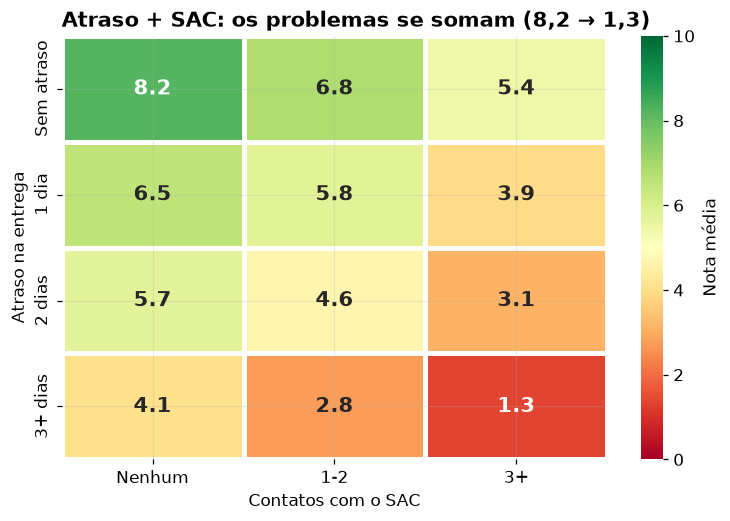

In [12]:
delay_groups = pd.cut(df["delivery_delay_days"], bins=[-1, 0, 1, 2, 99], labels=["Sem atraso", "1 dia", "2 dias", "3+ dias"])
contact_groups = pd.cut(df["customer_service_contacts"], bins=[-1, 0, 2, 99], labels=["Nenhum", "1-2", "3+"])
heatmap_data = df.pivot_table(index=delay_groups, columns=contact_groups, values="nps_score", aggfunc="mean", observed=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="RdYlGn", vmin=0, vmax=10,
            linewidths=2, cbar_kws={"label": "Nota média"}, ax=ax, annot_kws={"fontsize": 14, "fontweight": "bold"})
ax.set_xlabel("Contatos com o SAC")
ax.set_ylabel("Atraso na entrega")
ax.set_title("Atraso + SAC: os problemas se somam (8,2 → 1,3)")
save_figure(fig, "fig07_atraso_x_sac.png")
plt.show()

In [13]:
friction_signals = pd.DataFrame({
    "atraso_2_dias_ou_mais": df["delivery_delay_days"] >= 2,
    "reclamacoes_4_ou_mais": df["complaints_count"] >= 4,
    "contatos_sac_2_ou_mais": df["customer_service_contacts"] >= 2,
    "resolucao_7_dias_ou_mais": df["resolution_time_days"] >= 7,
})
df["journey_problems"] = friction_signals.sum(axis=1)

print("% de pedidos com cada sinal de atrito:")
print(friction_signals.mean().mul(100).round(0).to_string())

friction_summary = summarize_by_group(df, "journey_problems")
friction_summary

% de pedidos com cada sinal de atrito:
atraso_2_dias_ou_mais       64.0
reclamacoes_4_ou_mais       63.0
contatos_sac_2_ou_mais      45.0
resolucao_7_dias_ou_mais    42.0


,pedidos,nota_media,pct_detratores,pct_promotores,nps
journey_problems,,,,,
0,206,7.46,38.35,26.70,-11.7
1,561,5.56,72.91,6.42,-66.5
2,699,4.56,87.70,2.29,-85.4
3,731,3.31,97.13,0.41,-96.7
4,303,2.24,98.35,0.00,-98.4


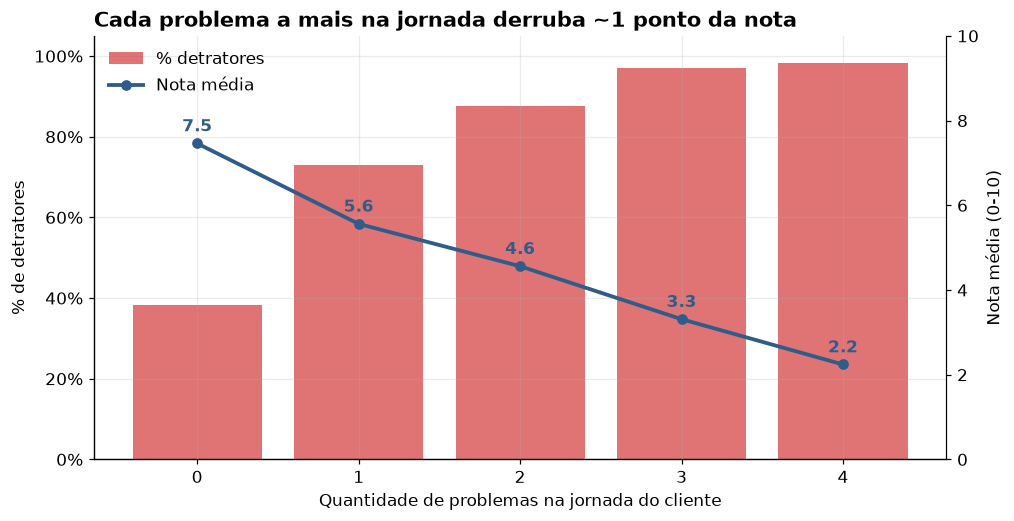

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_score_and_detractors(friction_summary, "Cada problema a mais na jornada derruba ~1 ponto da nota",
                          "Quantidade de problemas na jornada do cliente", ax=ax)
save_figure(fig, "fig08_problemas_na_jornada.png")
plt.show()

**Em linguagem de gestão:**
- **Sim, existe ponto de ruptura.** Ele acontece a partir de **2 dias de atraso** ou da **2ª reclamação**. Depois disso, praticamente não existem mais promotores (2% ou menos).
- Os problemas **se somam**: sem atraso e sem SAC, a nota média é **8,2** (perto de promotor). Com 3+ dias de atraso e 3+ contatos, cai para **1,3**.
- Clientes **sem nenhum problema** na jornada têm nota 7,5 e **27% de promotores**. Com **2 problemas** já são 88% de detratores. Com **3 ou mais**, praticamente 100%.
- A empresa não precisa de uma jornada perfeita para ter promotores, mas **não pode deixar os problemas se acumularem**.

## 5. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

In [15]:
profile_comparison = pd.DataFrame({
    "Promotores": df[df["nps_category"] == "Promotor"].mean(numeric_only=True),
    "Neutros": df[df["nps_category"] == "Neutro"].mean(numeric_only=True),
    "Detratores": df[df["nps_category"] == "Detrator"].mean(numeric_only=True),
}).loc[[
    "delivery_delay_days", "complaints_count", "customer_service_contacts", "resolution_time_days",
    "customer_age", "customer_tenure_months", "order_value", "freight_value", "payment_installments",
]].round(2)
profile_comparison.index = [
    "Dias de atraso (média)", "Reclamações (média)", "Contatos com SAC (média)", "Tempo de resolução (média)",
    "Idade (média)", "Tempo de relacionamento (meses)", "Valor do pedido (R$)", "Frete (R$)", "Parcelas",
]
profile_comparison.loc["% de pedidos com atraso"] = [
    round(df.loc[df["nps_category"] == c, "has_delay"].mean() * 100, 1) for c in ["Promotor", "Neutro", "Detrator"]
]
profile_comparison

,Promotores,Neutros,Detratores
Dias de atraso (média),0.72,1.05,2.41
Reclamações (média),2.27,2.69,4.44
Contatos com SAC (média),0.67,1.01,1.63
Tempo de resolução (média),3.70,4.62,5.69
Idade (média),43.63,43.25,43.40
Tempo de relacionamento (meses),63.00,59.83,61.43
Valor do pedido (R$),468.08,458.17,429.31
Frete (R$),37.05,38.06,38.30
Parcelas,5.81,6.28,5.98
% de pedidos com atraso,54.50,70.10,93.20


**Em linguagem de gestão:**

O que diferencia promotores de detratores **não é quem o cliente é, e sim o que aconteceu com ele.**

Repare também que **55% dos promotores tiveram algum atraso**. Um atraso pequeno, sozinho, não destrói a experiência. O que destrói é o **atraso grande somado a reclamações e SAC**.

| | Cliente promotor típico | Cliente detrator típico |
|---|---|---|
| Atraso | Em média **menos de 1 dia** (0,7) | Mais de **2 dias** (2,4) |
| Pedidos com atraso | 55% | 93% |
| Reclamações | Cerca de **2** | Mais de **4** |
| SAC | **Menos de 1 contato** (0,7) | **1 a 2 contatos** (1,6) |
| Idade, região, valor gasto | Iguais | Iguais |

👉 **NPS alto:** pedido no prazo, sem reclamação e sem precisar do SAC.
👉 **NPS baixo:** pedido atrasado, com várias reclamações e idas e vindas no SAC, **independentemente do perfil**.

## 6. Por que isso importa? NPS e recompra

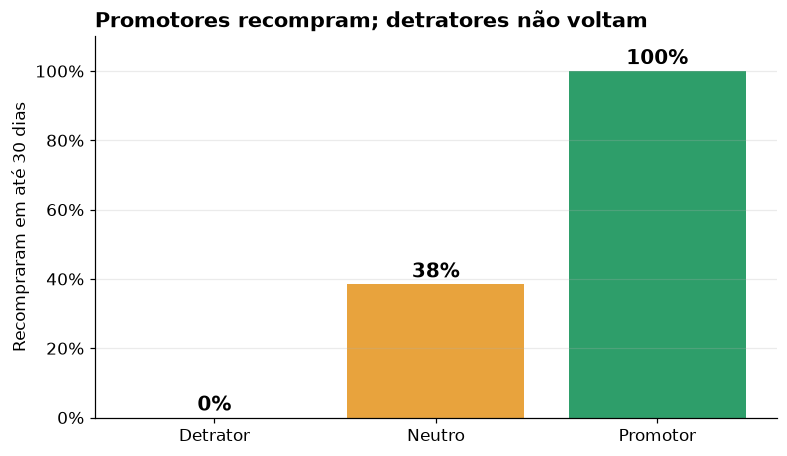

In [16]:
repurchase = df.groupby("nps_category", observed=True)["repeat_purchase_30d"].mean().mul(100)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(repurchase.index.astype(str), repurchase.values,
              color=[config.COLOR_DETRACTOR, config.COLOR_NEUTRAL, config.COLOR_PROMOTER])
for bar, value in zip(bars, repurchase.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2, f"{value:.0f}%", ha="center", fontweight="bold", fontsize=13)
ax.set_ylim(0, 110)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylabel("Recompraram em até 30 dias")
ax.set_title("Promotores recompram; detratores não voltam")
ax.grid(axis="x", visible=False)
save_figure(fig, "fig09_recompra_por_categoria.png")
plt.show()

**Em linguagem de gestão:**
- **Nenhum detrator** voltou a comprar em 30 dias. **38% dos neutros** e **100% dos promotores** voltaram.
- Com 84% de detratores, a empresa está **perdendo a recompra de quase toda a base**. Melhorar o NPS não é "vaidade", é **receita recorrente**.

> ⚠️ Lembrete técnico: por ser uma consequência da satisfação, a recompra **não** entra como variável do modelo preditivo (ver notebook 01).

## Resumo executivo da EDA

1. **NPS de -80**: 84% dos clientes são detratores. Situação crítica.
2. **Fator nº 1: atraso na entrega.** 89% dos pedidos atrasam, e cada dia de atraso custa cerca de 1 ponto de nota.
3. **Fator nº 2: reclamações e SAC.** Cada reclamação e cada contato extra derrubam a nota.
4. **Ponto de ruptura:** 2 dias de atraso ou 2 reclamações. A partir daí, quase não há promotores.
5. **Os problemas se somam:** sem atraso e sem SAC a nota é 8,2. Com muito atraso e muito SAC, cai para 1,3.
6. **Perfil, preço, desconto e região não explicam a nota.** O problema é **operacional**, não de público.
7. **Promotores recompram (100%), detratores não (0%).** Melhorar o NPS protege a receita.

➡️ Próximo passo: `03_modelo_preditivo.ipynb`